<a href="https://colab.research.google.com/github/Ernilla12/DATA-COMPETITION-ISFEST-2026-Mapping-the-Demand-for-Electric-Vehicle-EV-Charging-Infrastructure-/blob/main/DataDuo_Penyisihan_Datcom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# install model xgboost
!pip install xgboost
!pip install -q catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.4 MB/s eta 0:00:00


In [ ]:
# install model lightgbm
!pip install lightgbm

In [ ]:
# Import library terlebih dahulu agar bisa di jalankan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import lightgbm as lgb

sns.set(style="whitegrid")
pd.set_option('display.max_columns', None)
from catboost import CatBoostRegressor


2. DATA UNDERSTANDING

In [ ]:
# 2.1 Load Dataset dari dataset train.csv
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DATADUO_LOMBA/train.csv')
df.head(10)
print("Shape train:", df.shape)


Shape train: (1054200, 21)


In [ ]:
# 2.2 Mengecek daftar kolom
print("Daftar kolom:", df.head().T)

Daftar kolom:                                                  0  \
id                                      TRN_U8DHEL   
timestamp                      2025-07-01 00:00:00   
station_id                                 EV00001   
station_name          ChargePoint - Los Angeles #1   
network                                ChargePoint   
city                                   Los Angeles   
state                                           CA   
latitude                                 34.012362   
longitude                              -118.114786   
location_type                      Shopping Center   
charger_type                        DC Fast Charge   
power_output_kw                               19.2   
amenities_nearby                             Hotel   
ports_total                                      6   
utilization_rate                             0.131   
pricing_type                               per_kwh   
temperature_f                                 98.6   
precipitation_

In [ ]:
# 2.3 Identifikasi Isi & Variabel Data
print("\n=== 2.2 Identifikasi Isi & Variabel Data ===")
print("Jumlah baris:", df.shape[0], "| Jumlah kolom:", df.shape[1])
print("Daftar kolom:", df.columns.tolist())
print("Tipe data tiap kolom:\n", df.dtypes)
print("Jumlah stasiun unik:", df['station_id'].nunique())
print("Jumlah timestamp unik:", df['timestamp'].nunique())
print("-> Data ini longitudinal: tiap stasiun punya rekaman tiap 30 menit sepanjang periode data.")


=== 2.2 Identifikasi Isi & Variabel Data ===
Jumlah baris: 1054200 | Jumlah kolom: 21
Daftar kolom: ['id', 'timestamp', 'station_id', 'station_name', 'network', 'city', 'state', 'latitude', 'longitude', 'location_type', 'charger_type', 'power_output_kw', 'amenities_nearby', 'ports_total', 'utilization_rate', 'pricing_type', 'temperature_f', 'precipitation_mm', 'weather_condition', 'gas_price_per_gallon', 'local_event']
Tipe data tiap kolom:
 id                       object
timestamp                object
station_id               object
station_name             object
network                  object
city                     object
state                    object
latitude                float64
longitude               float64
location_type            object
charger_type             object
power_output_kw         float64
amenities_nearby         object
ports_total               int64
utilization_rate        float64
pricing_type             object
temperature_f           float64
precipita

In [ ]:
# 2.4 Pengelompokan variabel berdasarkan hipotesis (untuk analisis nanti)
hipotesis_variabel = {
    "Lokasi": ["city", "state", "location_type"],
    "Waktu": ["hour", "day", "month", "is_weekend", "is_peak_hour"],
    "Infrastruktur": ["charger_type", "power_output_kw", "ports_total", "network"],
    "Fasilitas": ["amenities_nearby"],
    "Cuaca": ["temperature_f", "precipitation_mm", "weather_condition"],
    "Ekonomi": ["gas_price_per_gallon", "pricing_type"],
    "Event": ["local_event"],
}
for kategori, kolom in hipotesis_variabel.items():
    print(f"  {kategori}: {kolom}")


  Lokasi: ['city', 'state', 'location_type']
  Waktu: ['hour', 'day', 'month', 'is_weekend', 'is_peak_hour']
  Infrastruktur: ['charger_type', 'power_output_kw', 'ports_total', 'network']
  Fasilitas: ['amenities_nearby']
  Cuaca: ['temperature_f', 'precipitation_mm', 'weather_condition']
  Ekonomi: ['gas_price_per_gallon', 'pricing_type']
  Event: ['local_event']


In [ ]:
# 2.5 Format & Kelengkapan Data
print("\n=== Format & Kelengkapan Data ===")
print("Missing value per kolom:\n", df.isnull().sum())
print("Persentase missing value:\n", (df.isnull().sum() / len(df) * 100).round(2))
print("Jumlah baris duplikat:", df.duplicated().sum())


=== Format & Kelengkapan Data ===
Missing value per kolom:
 id                          0
timestamp                   0
station_id                  0
station_name                0
network                     0
city                        0
state                       0
latitude                    0
longitude                   0
location_type               0
charger_type                0
power_output_kw             0
amenities_nearby            0
ports_total                 0
utilization_rate            0
pricing_type                0
temperature_f           44160
precipitation_mm        24032
weather_condition           0
gas_price_per_gallon        0
local_event                 0
dtype: int64
Persentase missing value:
 id                      0.00
timestamp               0.00
station_id              0.00
station_name            0.00
network                 0.00
city                    0.00
state                   0.00
latitude                0.00
longitude               0.00
location

In [ ]:
# 2.6 Evaluasi Kualitas Data
print("\n=== Evaluasi Kualitas Data ===")

print("Range utilization_rate:", df['utilization_rate'].min(), "-", df['utilization_rate'].max())

for col in ['power_output_kw', 'ports_total', 'gas_price_per_gallon']:
    jumlah_negatif = (df[col] < 0).sum()
    status = f" {jumlah_negatif} nilai negatif" if jumlah_negatif > 0 else "tidak ada nilai negatif"
    print(f"  {col}: {status}")

print("\nDeteksi outlier (metode IQR):")
for col in ['power_output_kw', 'ports_total', 'temperature_f', 'precipitation_mm',
            'gas_price_per_gallon', 'utilization_rate']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    jumlah_outlier = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
    print(f"  - {col}: {jumlah_outlier} outlier (rentang wajar: {batas_bawah:.2f} s/d {batas_atas:.2f})")

print("\nKonsistensi nilai kategori:")
for col in ['network', 'city', 'state', 'location_type', 'charger_type',
            'pricing_type', 'weather_condition', 'local_event']:
    print(f"  - {col}: {df[col].nunique()} kategori unik")




=== Evaluasi Kualitas Data ===
Range utilization_rate: 0.02 - 0.98
  power_output_kw: tidak ada nilai negatif
  ports_total: tidak ada nilai negatif
  gas_price_per_gallon: tidak ada nilai negatif

Deteksi outlier (metode IQR):
  - power_output_kw: 0 outlier (rentang wajar: -327.00 s/d 596.20)
  - ports_total: 77308 outlier (rentang wajar: -2.00 s/d 14.00)
  - temperature_f: 40309 outlier (rentang wajar: 34.85 s/d 123.25)
  - precipitation_mm: 108162 outlier (rentang wajar: 0.00 s/d 0.00)
  - gas_price_per_gallon: 0 outlier (rentang wajar: 2.14 s/d 5.61)
  - utilization_rate: 0 outlier (rentang wajar: -0.65 s/d 1.40)

Konsistensi nilai kategori:
  - network: 8 kategori unik
  - city: 15 kategori unik
  - state: 13 kategori unik
  - location_type: 8 kategori unik
  - charger_type: 4 kategori unik
  - pricing_type: 3 kategori unik
  - weather_condition: 7 kategori unik
  - local_event: 5 kategori unik



=== Analisis Kumpulan Data (EDA Awal) ===
           latitude     longitude  power_output_kw   ports_total  \
count  1.054200e+06  1.054200e+06     1.054200e+06  1.054200e+06   
mean   3.744355e+01 -1.016788e+02     1.345880e+02  7.306667e+00   
std    5.894350e+00  1.751827e+01     1.285099e+02  4.483969e+00   
min    2.561943e+01 -1.228127e+02     7.200000e+00  2.000000e+00   
25%    3.348356e+01 -1.172766e+02     1.920000e+01  4.000000e+00   
50%    3.697384e+01 -1.050262e+02     1.000000e+02  6.000000e+00   
75%    4.197794e+01 -8.452968e+01     2.500000e+02  8.000000e+00   
max    4.772777e+01 -7.091298e+01     3.500000e+02  2.400000e+01   

       utilization_rate  temperature_f  precipitation_mm  gas_price_per_gallon  
count      1.054200e+06   1.010040e+06      1.030168e+06          1.054200e+06  
mean       4.070671e-01   7.715153e+01      5.306462e-01          3.890539e+00  
std        2.945973e-01   1.818816e+01      2.246561e+00          5.866540e-01  
min        2.000000e

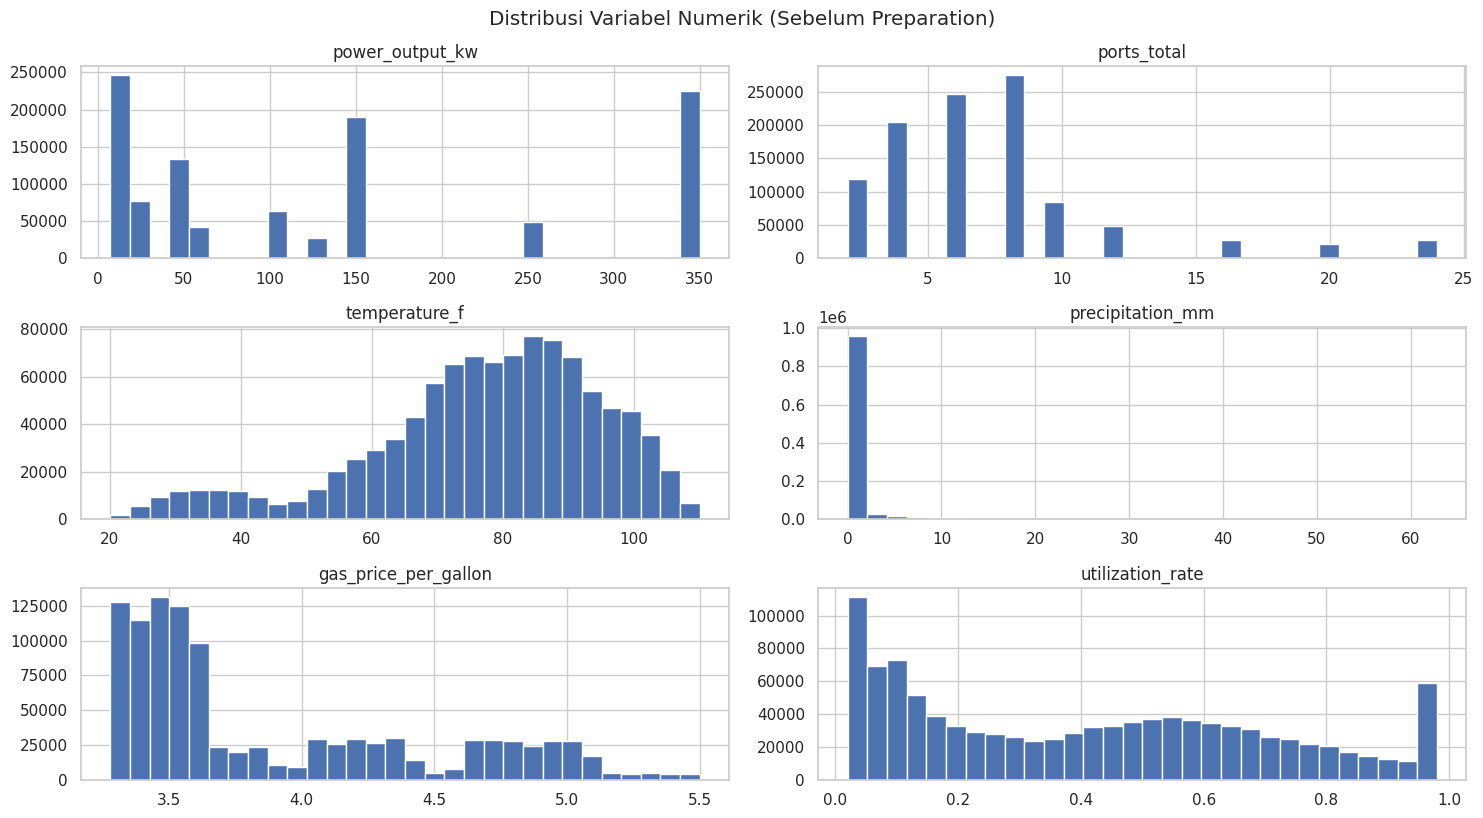

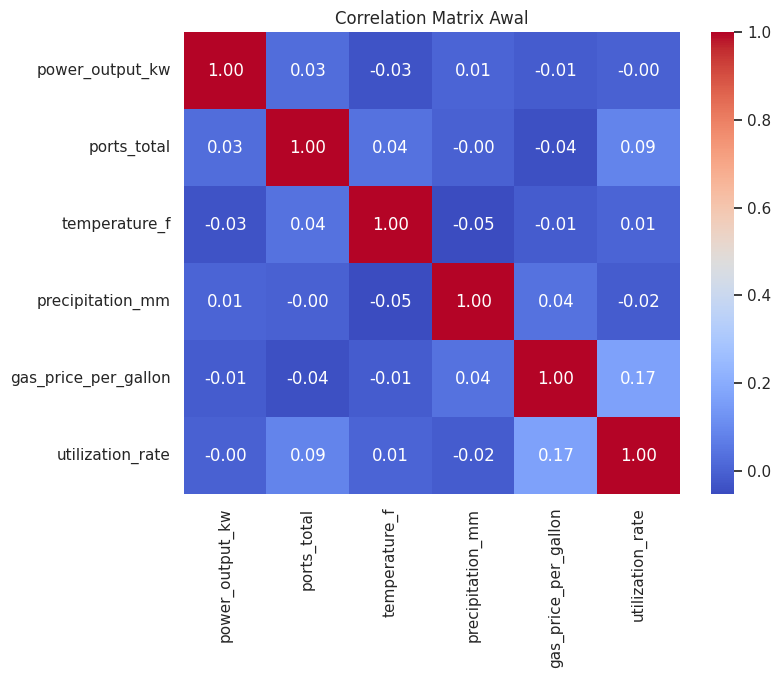

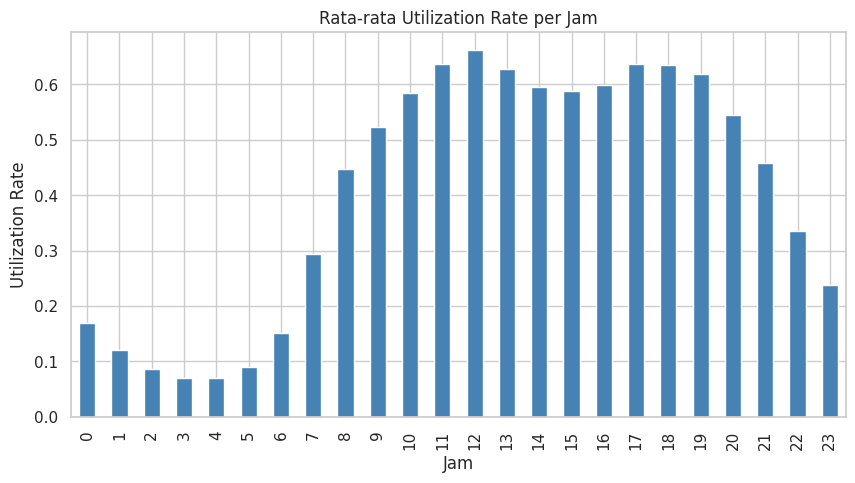

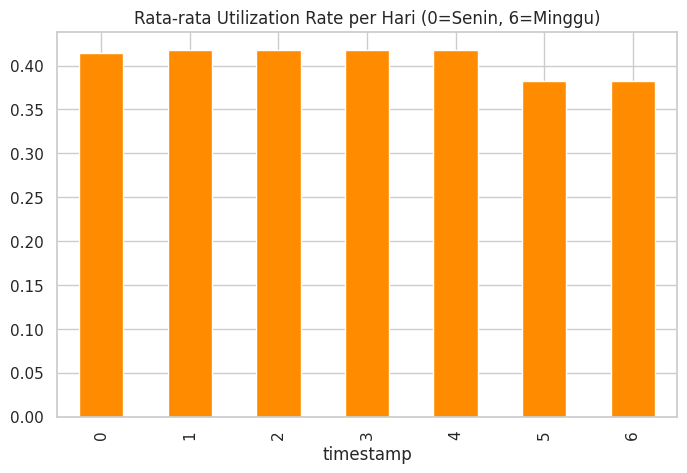

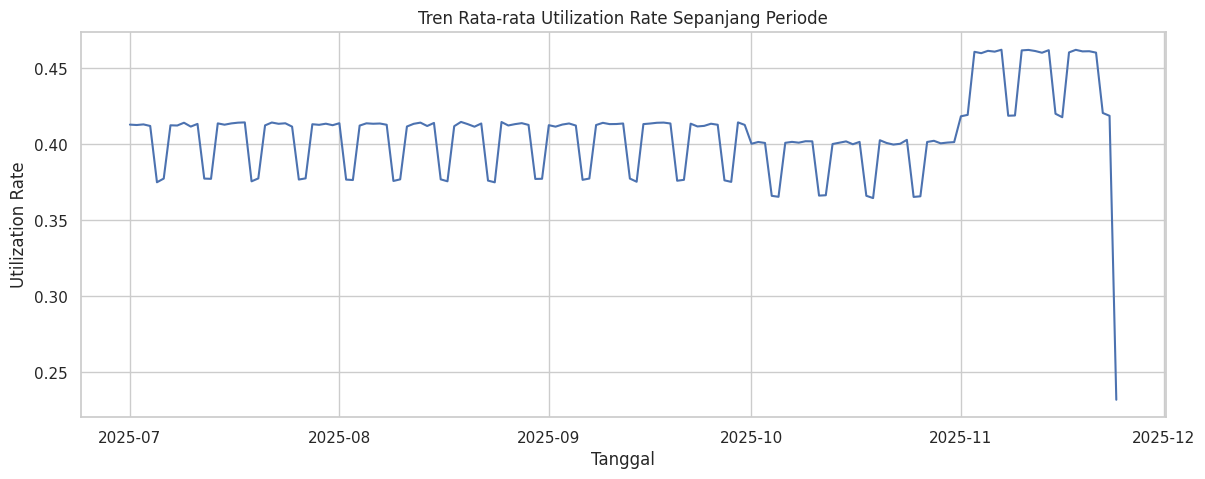

In [ ]:
# 2.7 EDA: Distribusi & Korelasi Awal
print("\n=== Analisis Kumpulan Data (EDA Awal) ===")
print(df.describe())

kolom_numerik_awal = ['power_output_kw', 'ports_total', 'temperature_f',
                       'precipitation_mm', 'gas_price_per_gallon', 'utilization_rate']
df[kolom_numerik_awal].hist(figsize=(15, 8), bins=30)
plt.tight_layout()
plt.suptitle("Distribusi Variabel Numerik (Sebelum Preparation)", y=1.02)
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[kolom_numerik_awal].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix Awal')
plt.show()

# Tren longitudinal (memanfaatkan struktur data time-series per stasiun)
df['timestamp'] = pd.to_datetime(df['timestamp'])

tren_jam = df.groupby(df['timestamp'].dt.hour)['utilization_rate'].mean()
plt.figure(figsize=(10, 5))
tren_jam.plot(kind='bar', color='steelblue')
plt.title('Rata-rata Utilization Rate per Jam')
plt.xlabel('Jam'); plt.ylabel('Utilization Rate')
plt.show()

tren_hari = df.groupby(df['timestamp'].dt.dayofweek)['utilization_rate'].mean()
plt.figure(figsize=(8, 5))
tren_hari.plot(kind='bar', color='darkorange')
plt.title('Rata-rata Utilization Rate per Hari (0=Senin, 6=Minggu)')
plt.show()

tren_harian = df.groupby(df['timestamp'].dt.date)['utilization_rate'].mean()
plt.figure(figsize=(14, 5))
tren_harian.plot()
plt.title('Tren Rata-rata Utilization Rate Sepanjang Periode')
plt.xlabel('Tanggal'); plt.ylabel('Utilization Rate')
plt.show()

3. DATA PREPARATION

In [ ]:
# 3.1 Select Data: tentukan kolom yang dipakai, buang identifier
# id & station_name = identifier murni, dibuang.
# station_id SENGAJA DIPERTAHANKAN sementara -> dipakai di tahap 3.5b untuk
# membangun fitur target-encoding per stasiun (baseline "ramainya" tiap
# stasiun), karena data ini longitudinal dan station_id yang sama muncul
# berulang di banyak timestamp (bahkan overlap dengan test.csv).
# station_id akan di-drop setelah fitur itu selesai dibuat (lihat 3.5b).
df = df.drop(columns=['id', 'station_name'])

In [ ]:
# 3.2 Data Cleaning: tangani missing value
df['month'] = df['timestamp'].dt.month

if df['temperature_f'].isnull().sum() > 0:
    df['temperature_f'] = df.groupby(['city', 'month'])['temperature_f'] \
                             .transform(lambda x: x.fillna(x.median()))
if df['precipitation_mm'].isnull().sum() > 0:
    df['precipitation_mm'] = df.groupby(['city', 'month'])['precipitation_mm'] \
                                .transform(lambda x: x.fillna(x.median()))
if df['ports_total'].isnull().sum() > 0:
    df['ports_total'] = df.groupby('city')['ports_total'].transform(lambda x: x.fillna(x.median()))
    df['ports_total'] = df['ports_total'].astype(int)

# Jaga-jaga: tangani sisa missing value di kolom lain yang mungkin belum ketahuan
sisa_numerik = df.select_dtypes(include=np.number).isnull().sum()
for col in sisa_numerik[sisa_numerik > 0].index:
    df[col] = df[col].fillna(df[col].median())

sisa_kategorikal = df.select_dtypes(include='object').isnull().sum()
for col in sisa_kategorikal[sisa_kategorikal > 0].index:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing value setelah cleaning:", df.isnull().sum().sum(), "(harus 0)")


Missing value setelah cleaning: 0 (harus 0)


In [ ]:
# 3 Data Cleaning: hapus duplikat
jumlah_duplikat = df.duplicated().sum()
if jumlah_duplikat > 0:
    df = df.drop_duplicates()
    print(f"Menghapus {jumlah_duplikat} baris duplikat")


In [ ]:
# 3.4 Data Cleaning: tangani outlier dengan capping (IQR)
# Capping dipilih (bukan hapus baris) karena outlier di dataset ini kemungkinan
# adalah kondisi nyata (charger sangat cepat, hujan sangat deras), bukan data error,
# dan dataset besar (1 juta+ baris) sehingga aman dipangkas tanpa kehilangan pola.
def cap_outlier_iqr(data, kolom):
    Q1, Q3 = data[kolom].quantile(0.25), data[kolom].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    data[kolom] = data[kolom].clip(lower, upper)
    return data

for col in ['power_output_kw', 'precipitation_mm', 'gas_price_per_gallon']:
    df = cap_outlier_iqr(df, col)


In [ ]:
# 3.5 Construct Data: buat fitur waktu (transform data)
df['hour'] = df['timestamp'].dt.hour
df['day'] = df['timestamp'].dt.dayofweek         # 0=Senin, 6=Minggu
df['is_weekend'] = df['day'].isin([5, 6]).astype(int)
df['is_peak_hour'] = df['hour'].apply(lambda h: 1 if (7 <= h <= 9) or (17 <= h <= 19) else 0).astype(int)
df = df.drop(columns=['timestamp'])

In [ ]:
# 3.5b Construct Data: Fitur Target-Encoding per Stasiun (K-Fold, smoothed, anti-leakage)
def smooth_target_encode(data, group_cols, target_col, global_mean, min_samples=30, smoothing=10):
    agg = data.groupby(group_cols)[target_col].agg(['mean', 'count'])
    weight = 1 / (1 + np.exp(-(agg['count'] - min_samples) / smoothing))
    agg['smoothed'] = global_mean * (1 - weight) + agg['mean'] * weight
    return agg['smoothed']

kf = KFold(n_splits=5, shuffle=True, random_state=42)
global_mean = df['utilization_rate'].mean()

df['station_avg_util'] = global_mean
df['station_hour_avg_util'] = global_mean
df['station_hour_weekend_avg_util'] = global_mean

for tr_idx, val_idx in kf.split(df):
    fold_train = df.iloc[tr_idx]
    fold_val = df.iloc[val_idx]

    map1 = smooth_target_encode(fold_train, ['station_id'], 'utilization_rate', global_mean)
    map2 = smooth_target_encode(fold_train, ['station_id', 'hour'], 'utilization_rate', global_mean)
    map3 = smooth_target_encode(fold_train, ['station_id', 'hour', 'is_weekend'], 'utilization_rate', global_mean)

    df.loc[fold_val.index, 'station_avg_util'] = fold_val['station_id'].map(map1).fillna(global_mean).values
    df.loc[fold_val.index, 'station_hour_avg_util'] = fold_val.set_index(['station_id', 'hour']).index.map(map2).values
    df.loc[fold_val.index, 'station_hour_weekend_avg_util'] = fold_val.set_index(['station_id', 'hour', 'is_weekend']).index.map(map3).values

df['station_hour_avg_util'] = df['station_hour_avg_util'].fillna(df['station_avg_util'])
df['station_hour_weekend_avg_util'] = df['station_hour_weekend_avg_util'].fillna(df['station_hour_avg_util'])

# Mapping FULL (dari seluruh train.csv) -- dipakai untuk test.csv di Tahap 6
station_avg_map_full = smooth_target_encode(df, ['station_id'], 'utilization_rate', global_mean)
station_hour_avg_map_full = smooth_target_encode(df, ['station_id', 'hour'], 'utilization_rate', global_mean)
station_hour_weekend_avg_map_full = smooth_target_encode(df, ['station_id', 'hour', 'is_weekend'], 'utilization_rate', global_mean)

# Simpan station_id untuk CatBoost (model ini dapat memanfaatkan kategori stasiun secara langsung).
station_id_for_cb = df['station_id'].astype(str).copy()
df = df.drop(columns=['station_id'])
print("Fitur station_avg_util, station_hour_avg_util, station_hour_weekend_avg_util berhasil dibuat")
print(df[['station_avg_util', 'station_hour_avg_util', 'station_hour_weekend_avg_util']].describe())

Fitur station_avg_util, station_hour_avg_util, station_hour_weekend_avg_util berhasil dibuat
       station_avg_util  station_hour_avg_util  station_hour_weekend_avg_util
count      1.054200e+06           1.054200e+06                   1.054200e+06
mean       4.070708e-01           4.070654e-01                   4.072563e-01
std        9.639257e-02           2.756444e-01                   2.834300e-01
min        2.195881e-01           2.008850e-02                   2.012765e-02
25%        3.416772e-01           1.270000e-01                   1.268557e-01
50%        3.995559e-01           4.269788e-01                   4.059277e-01
75%        4.781721e-01           6.411068e-01                   6.349903e-01
max        6.436999e-01           9.758628e-01                   9.799998e-01


In [ ]:
# 3.6 Construct Data: fitur dari amenities_nearby (multi-value)
df['jumlah_amenities'] = df['amenities_nearby'].apply(lambda x: len(str(x).split(',')))

amenity_list = df['amenities_nearby'].apply(lambda x: [a.strip() for a in str(x).split(',')])
mlb = MultiLabelBinarizer()
amenity_encoded = pd.DataFrame(
    mlb.fit_transform(amenity_list),
    columns=[f"amenity_{a.replace(' ', '_')}" for a in mlb.classes_],
    index=df.index
)
df = pd.concat([df, amenity_encoded], axis=1).drop(columns=['amenities_nearby'])

In [ ]:
# 3.7 Transform Data: encoding kategori nominal
# Tidak ada kategori ORDINAL di dataset ini, semua kategori bersifat NOMINAL
# (tidak ada urutan/tingkatan), jadi cukup pakai get_dummies (bukan LabelEncoder)
kolom_nominal = ['network', 'city', 'state', 'location_type', 'charger_type',
                  'pricing_type', 'weather_condition', 'local_event']
df = pd.get_dummies(df, columns=kolom_nominal, drop_first=True)
print("Jumlah kolom setelah encoding:", df.shape[1])


Jumlah kolom setelah encoding: 82


In [ ]:
# 3.8 Menentukan Variabel Target & Prediktor
target = 'utilization_rate'
fitur_prediktor = [col for col in df.columns if col != target]
X = df[fitur_prediktor]
y = df[target]
print("Jumlah fitur prediktor:", X.shape[1])

Jumlah fitur prediktor: 81


In [ ]:
# 3.9 Split Data Training & Validasi
# pemisahan internal dari train.csv untuk
# menghitung RMSE sebelum model dipakai memprediksi test.csv yang sebenarnya.
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data training:", X_train.shape[0], "| Data validasi:", X_val.shape[0])

Data training: 843360 | Data validasi: 210840


In [ ]:
# ============================================================
# V4.1 — SIAPKAN DATA HISTORIS PER STATION
# ============================================================
# Tujuan:
# Membuat fitur utilization sebelumnya:
# lag 30 menit, 1 jam, 1.5 jam, 24 jam, 48 jam, 7 hari
#
# Fitur hanya menggunakan data sebelum timestamp sekarang.
# Jadi target masa depan tidak ikut digunakan.

df_history = pd.read_csv(
    '/content/drive/MyDrive/DATADUO_LOMBA/train.csv'
)

df_history['timestamp'] = pd.to_datetime(df_history['timestamp'])

# index asli harus sama dengan df setelah preprocessing
df_history = df_history.loc[df.index].copy()

print("History shape:", df_history.shape)
print("Station:", df_history['station_id'].nunique())
print(
    "Timestamp:",
    df_history['timestamp'].min(),
    "s/d",
    df_history['timestamp'].max()
)

History shape: (1054200, 21)
Station: 150
Timestamp: 2025-07-01 00:00:00 s/d 2025-11-24 09:30:00


In [ ]:
# ============================================================
# V4.2 — FUNGSI MEMBUAT LAG FEATURES
# ============================================================

def make_lag_features(history_df, target_df):
    """
    history_df:
        data yang target utilization_rate-nya boleh digunakan
        sebagai histori.

    target_df:
        baris yang ingin diberi fitur lag.

    Semua lag dicari berdasarkan:
        station_id + timestamp
    """

    hist = history_df[
        ['station_id', 'timestamp', 'utilization_rate']
    ].copy()

    target = target_df[
        ['station_id', 'timestamp']
    ].copy()

    hist = hist.sort_values(
        ['station_id', 'timestamp']
    )

    target = target.sort_values(
        ['station_id', 'timestamp']
    )

    # --------------------------------------------------------
    # MAP TARGET BERDASARKAN STATION + TIMESTAMP
    # --------------------------------------------------------

    hist_map = hist.set_index(
        ['station_id', 'timestamp']
    )['utilization_rate']

    result = pd.DataFrame(index=target.index)

    # 30 menit
    lag_minutes = {
        'lag_30m': 30,
        'lag_1h': 60,
        'lag_1_5h': 90,
        'lag_2h': 120,
        'lag_24h': 1440,
        'lag_48h': 2880,
        'lag_7d': 10080
    }

    for name, minutes in lag_minutes.items():

        lookup_time = (
            target['timestamp']
            - pd.Timedelta(minutes=minutes)
        )

        keys = pd.MultiIndex.from_arrays(
            [
                target['station_id'].values,
                lookup_time.values
            ],
            names=['station_id', 'timestamp']
        )

        result[name] = keys.map(hist_map).values

    return result


print("Fungsi lag berhasil dibuat.")

Fungsi lag berhasil dibuat.


In [ ]:
# ============================================================
# V4.3 — LAG TRAIN & VALIDATION TANPA LEAKAGE
# ============================================================

# Index dari split yang sudah dibuat di Cell 22
train_idx = X_train.index
val_idx = X_val.index

# ------------------------------------------------------------
# DATA HISTORI UNTUK TRAIN
# HANYA BARIS TRAIN
# ------------------------------------------------------------

history_train = df_history.loc[
    train_idx,
    ['station_id', 'timestamp', 'utilization_rate']
].copy()

target_train = df_history.loc[
    train_idx,
    ['station_id', 'timestamp']
].copy()

lag_train = make_lag_features(
    history_train,
    target_train
)

# ------------------------------------------------------------
# DATA HISTORI UNTUK VALIDASI
#
# Validation hanya boleh menggunakan target TRAIN.
# ------------------------------------------------------------

target_val = df_history.loc[
    val_idx,
    ['station_id', 'timestamp']
].copy()

lag_val = make_lag_features(
    history_train,
    target_val
)

# Kembalikan sesuai index asli
lag_train = lag_train.reindex(train_idx)
lag_val = lag_val.reindex(val_idx)

print("Lag train:", lag_train.shape)
print("Lag val  :", lag_val.shape)

print("\nMissing lag TRAIN:")
print(lag_train.isnull().mean().sort_values())

print("\nMissing lag VALIDASI:")
print(lag_val.isnull().mean().sort_values())

Lag train: (843360, 7)
Lag val  : (210840, 7)

Missing lag TRAIN:
lag_30m     0.199953
lag_1h      0.200191
lag_2h      0.200240
lag_1_5h    0.200327
lag_24h     0.205641
lag_48h     0.210795
lag_7d      0.238082
dtype: float64

Missing lag VALIDASI:
lag_1h      0.200308
lag_1_5h    0.200341
lag_30m     0.200730
lag_2h      0.201247
lag_24h     0.204620
lag_48h     0.211198
lag_7d      0.238228
dtype: float64


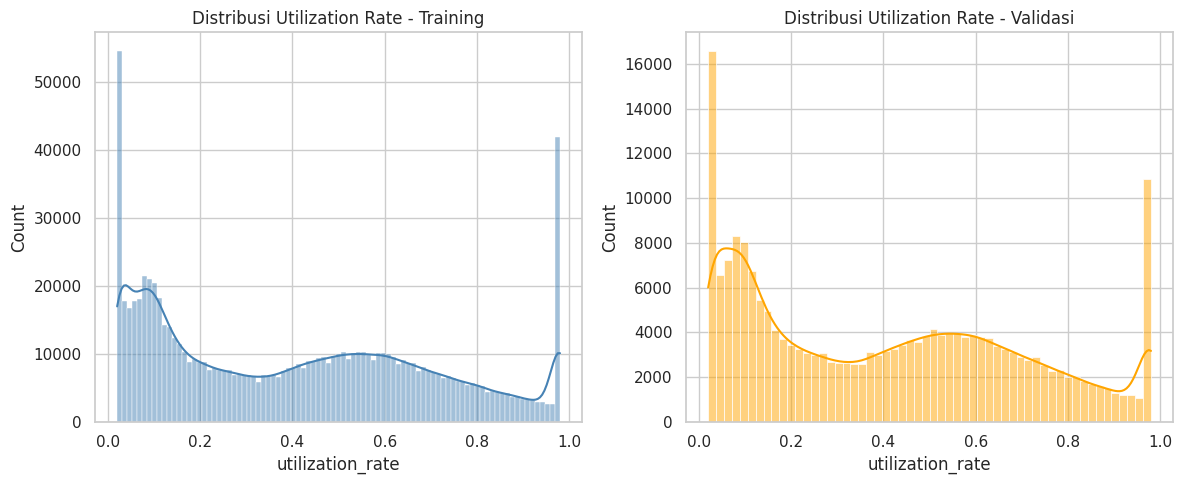

In [ ]:
#  3.10 Visualisasi Distribusi Target: Training vs Validasi
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(y_train, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Utilization Rate - Training')
sns.histplot(y_val, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribusi Utilization Rate - Validasi')
plt.tight_layout()
plt.show()

4. MODELING

In [ ]:
xgb_params = dict(
    n_estimators=5000, learning_rate=0.02, max_depth=9,
    min_child_weight=3, subsample=0.85, colsample_bytree=0.7,
    colsample_bynode=0.8, reg_lambda=1.5, reg_alpha=0.2,
    random_state=42, n_jobs=-1, objective='reg:squarederror',
    early_stopping_rounds=80,
)

lgbm_params = dict(
    n_estimators=5000, learning_rate=0.02, max_depth=-1,
    num_leaves=127, min_child_samples=20, subsample=0.85,
    colsample_bytree=0.7, reg_lambda=1.5, reg_alpha=0.2,
    random_state=42, n_jobs=-1, verbose=-1,
)

model_terlatih = {}
hasil_evaluasi = []
val_predictions = {}

In [ ]:
xgb_model = XGBRegressor(**xgb_params)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
model_terlatih["XGBoost"] = xgb_model
print("XGBoost selesai | best_iteration:", xgb_model.best_iteration)

XGBoost selesai | best_iteration: 387


In [ ]:
lgbm_model = LGBMRegressor(**lgbm_params)
lgbm_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
               callbacks=[lgb.early_stopping(50, verbose=False)])
model_terlatih["LightGBM"] = lgbm_model
print("LightGBM selesai | best_iteration:", lgbm_model.best_iteration_)

LightGBM selesai | best_iteration: 532


In [ ]:
for nama_model, model in model_terlatih.items():
    y_pred_train = model.predict(X_train)
    y_pred_val = model.predict(X_val)
    val_predictions[nama_model] = y_pred_val

    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
    mae_val = mean_absolute_error(y_val, y_pred_val)
    r2_val = r2_score(y_val, y_pred_val)

    hasil_evaluasi.append({
        "Model": nama_model, "RMSE Train": rmse_train, "RMSE Validasi": rmse_val,
        "MAE Validasi": mae_val, "R2 Validasi": r2_val
    })
    print(f"{nama_model:20s} | RMSE Train: {rmse_train:.4f} | RMSE Val: {rmse_val:.4f} | "
          f"MAE Val: {mae_val:.4f} | R2 Val: {r2_val:.4f}")

XGBoost              | RMSE Train: 0.0642 | RMSE Val: 0.0654 | MAE Val: 0.0468 | R2 Val: 0.9507
LightGBM             | RMSE Train: 0.0643 | RMSE Val: 0.0654 | MAE Val: 0.0469 | R2 Val: 0.9507


In [ ]:
best_w, best_rmse_blend = 0.5, np.inf
for w in np.arange(0.0, 1.01, 0.05):
    blend_val = w * val_predictions["XGBoost"] + (1 - w) * val_predictions["LightGBM"]
    rmse_blend = np.sqrt(mean_squared_error(y_val, blend_val))
    if rmse_blend < best_rmse_blend:
        best_rmse_blend, best_w = rmse_blend, w

blend_weight_xgb = best_w
blend_val_final = blend_weight_xgb * val_predictions["XGBoost"] + (1 - blend_weight_xgb) * val_predictions["LightGBM"]
print(f"Blend terbaik: {blend_weight_xgb:.2f}*XGBoost + {1-blend_weight_xgb:.2f}*LightGBM "
      f"| RMSE Val: {best_rmse_blend:.4f}")

hasil_evaluasi.append({
    "Model": "Blend (XGB+LightGBM)",
    "RMSE Train": np.nan,
    "RMSE Validasi": best_rmse_blend,
    "MAE Validasi": mean_absolute_error(y_val, blend_val_final),
    "R2 Validasi": r2_score(y_val, blend_val_final),
})

Blend terbaik: 0.40*XGBoost + 0.60*LightGBM | RMSE Val: 0.0654


### 4.1b CatBoost + Ensemble (tambahan untuk menurunkan RMSE)
CatBoost dicoba sebagai model ketiga. Bobot ensemble dicari berdasarkan prediksi validasi sehingga CatBoost hanya dipakai jika benar-benar memperbaiki RMSE.


In [ ]:
# ============================================================
# 4.1b CATBOOST
# ============================================================
# Gunakan fitur X yang sama dengan XGB/LGB + station_id sebagai categorical feature.
X_cb = X.copy()
X_cb['station_id'] = station_id_for_cb.values
X_cb['station_id'] = X_cb['station_id'].fillna('__MISSING__').astype(str)

X_cb_train, X_cb_val, y_cb_train, y_cb_val = train_test_split(
    X_cb, y, test_size=0.2, random_state=42
)
# Pastikan split identik dengan X_train/X_val berdasarkan index
X_cb_train = X_cb.loc[X_train.index]
X_cb_val = X_cb.loc[X_val.index]
y_cb_train = y_train
y_cb_val = y_val

cat_idx = [X_cb.columns.get_loc('station_id')]

cb_model = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.035,
    depth=8,
    loss_function='RMSE',
    eval_metric='RMSE',
    l2_leaf_reg=6,
    random_seed=42,
    random_strength=0.5,
    border_count=128,
    od_type='Iter',
    od_wait=150,
    verbose=200,
    allow_writing_files=False,
    thread_count=-1
)

cb_model.fit(
    X_cb_train, y_cb_train,
    cat_features=cat_idx,
    eval_set=(X_cb_val, y_cb_val),
    use_best_model=True
)

pred_cb = cb_model.predict(X_cb_val)
rmse_cb = np.sqrt(mean_squared_error(y_val, pred_cb))
print(f"CatBoost RMSE: {rmse_cb:.6f} | best_iteration={cb_model.get_best_iteration()}")

model_terlatih['CatBoost'] = cb_model
val_predictions['CatBoost'] = pred_cb
hasil_evaluasi.append({
    'Model':'CatBoost', 'RMSE Train':np.nan,
    'RMSE Validasi':rmse_cb,
    'MAE Validasi':mean_absolute_error(y_val,pred_cb),
    'R2 Validasi':r2_score(y_val,pred_cb)
})


0:	learn: 0.2850384	test: 0.2849576	best: 0.2849576 (0)	total: 631ms	remaining: 52m 34s
200:	learn: 0.0652991	test: 0.0654941	best: 0.0654941 (200)	total: 2m	remaining: 48m 2s
400:	learn: 0.0651607	test: 0.0654659	best: 0.0654656 (395)	total: 4m 3s	remaining: 46m 37s
600:	learn: 0.0650541	test: 0.0654479	best: 0.0654477 (595)	total: 5m 49s	remaining: 42m 36s
800:	learn: 0.0649444	test: 0.0654442	best: 0.0654438 (770)	total: 7m 37s	remaining: 39m 56s
1000:	learn: 0.0648296	test: 0.0654432	best: 0.0654418 (886)	total: 9m 27s	remaining: 37m 46s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.06544182996
bestIteration = 886

Shrink model to first 887 iterations.
CatBoost RMSE: 0.065442 | best_iteration=886


In [ ]:
# ============================================================
# 4.1c ENSEMBLE 3 MODEL: XGB + LGBM + CATBOOST
# ============================================================
# Grid bobot 1% cukup rapat; total bobot = 1.
best = (None, np.inf)
px = val_predictions['XGBoost']
pl = val_predictions['LightGBM']
pc = val_predictions['CatBoost']

for wx in np.arange(0, 1.001, 0.01):
    for wl in np.arange(0, 1.001-wx, 0.01):
        wc = 1.0 - wx - wl
        pred = wx*px + wl*pl + wc*pc
        rmse = np.sqrt(mean_squared_error(y_val, pred))
        if rmse < best[1]:
            best = ((float(wx), float(wl), float(wc)), float(rmse))

(w_xgb, w_lgb, w_cb), rmse_ensemble3 = best
pred_ensemble3 = w_xgb*px + w_lgb*pl + w_cb*pc
print(f"Ensemble 3 model: XGB={w_xgb:.2f}, LGBM={w_lgb:.2f}, CatBoost={w_cb:.2f}")
print(f"RMSE Ensemble 3: {rmse_ensemble3:.6f}")

hasil_evaluasi.append({
    'Model':'Ensemble (XGB+LGBM+CatBoost)',
    'RMSE Train':np.nan,
    'RMSE Validasi':rmse_ensemble3,
    'MAE Validasi':mean_absolute_error(y_val,pred_ensemble3),
    'R2 Validasi':r2_score(y_val,pred_ensemble3)
})

# Pastikan hasil evaluasi diperbarui sebelum tabel perbandingan cell berikutnya.
df_hasil = pd.DataFrame(hasil_evaluasi).sort_values('RMSE Validasi').reset_index(drop=True)
print('\n=== PERBANDINGAN SETELAH CATBOOST ===')
print(df_hasil.to_string(index=False))


Ensemble 3 model: XGB=0.28, LGBM=0.49, CatBoost=0.23
RMSE Ensemble 3: 0.065347

=== PERBANDINGAN SETELAH CATBOOST ===
                       Model  RMSE Train  RMSE Validasi  MAE Validasi  R2 Validasi
Ensemble (XGB+LGBM+CatBoost)         NaN       0.065347      0.046833     0.950774
        Blend (XGB+LightGBM)         NaN       0.065356      0.046851     0.950761
                    LightGBM    0.064340       0.065371      0.046884     0.950738
                     XGBoost    0.064184       0.065386      0.046847     0.950715
                    CatBoost         NaN       0.065442      0.046876     0.950631


In [ ]:
# Stacking Ridge lama sengaja tidak digunakan: meta-model dilatih pada validation prediction yang sama, sehingga RMSE menjadi optimistis/leakage.
print('Stacking Ridge dilewati untuk evaluasi yang fair.')


Stacking Ridge dilewati untuk evaluasi yang fair.


5. EVALUATION


=== Perbandingan RMSE Antar Model ===
                       Model  RMSE Train  RMSE Validasi  MAE Validasi  R2 Validasi
Ensemble (XGB+LGBM+CatBoost)         NaN       0.065347      0.046833     0.950774
        Blend (XGB+LightGBM)         NaN       0.065356      0.046851     0.950761
                    LightGBM    0.064340       0.065371      0.046884     0.950738
                     XGBoost    0.064184       0.065386      0.046847     0.950715
                    CatBoost         NaN       0.065442      0.046876     0.950631


/tmp/ipykernel_1913/2235728160.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_hasil, x="Model", y="RMSE Validasi", palette="viridis")


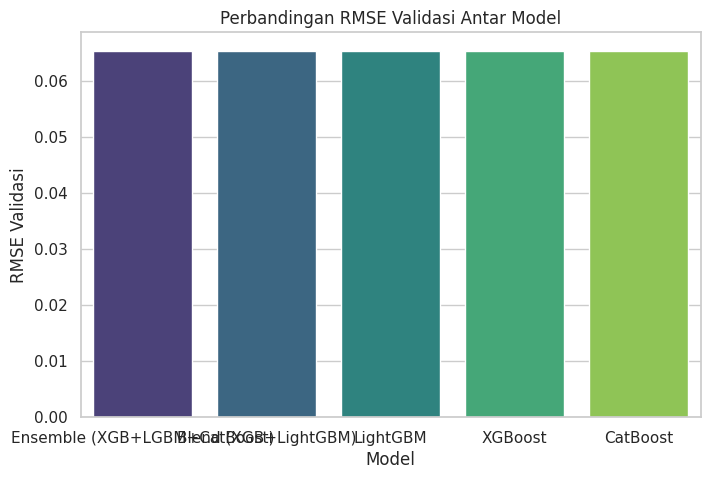

In [ ]:
# 5.1 Tabel Perbandingan RMSE
df_hasil = pd.DataFrame(hasil_evaluasi).sort_values("RMSE Validasi")
print("\n=== Perbandingan RMSE Antar Model ===")
print(df_hasil.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=df_hasil, x="Model", y="RMSE Validasi", palette="viridis")
plt.title("Perbandingan RMSE Validasi Antar Model")
plt.show()

In [ ]:
# 5.2 Cek Overfitting
df_hasil["Selisih (Val - Train)"] = df_hasil["RMSE Validasi"] - df_hasil["RMSE Train"]
print("\n=== Cek Indikasi Overfitting ===")
print(df_hasil[["Model", "RMSE Train", "RMSE Validasi", "Selisih (Val - Train)"]].to_string(index=False))



=== Cek Indikasi Overfitting ===
                       Model  RMSE Train  RMSE Validasi  Selisih (Val - Train)
Ensemble (XGB+LGBM+CatBoost)         NaN       0.065347                    NaN
        Blend (XGB+LightGBM)         NaN       0.065356                    NaN
                    LightGBM    0.064340       0.065371               0.001031
                     XGBoost    0.064184       0.065386               0.001203
                    CatBoost         NaN       0.065442                    NaN


In [ ]:
model_terbaik_nama = df_hasil.iloc[0]['Model']
is_ensemble3 = (model_terbaik_nama == 'Ensemble (XGB+LGBM+CatBoost)')
is_blend = (model_terbaik_nama == 'Blend (XGB+LightGBM)')

if is_ensemble3:
    model_terbaik = None
    print(f'>>> Model terbaik: {model_terbaik_nama} (XGB={w_xgb:.2f}, LGBM={w_lgb:.2f}, CatBoost={w_cb:.2f})')
elif is_blend:
    model_terbaik = None
    print(f'>>> Model terbaik: {model_terbaik_nama} (bobot XGB={blend_weight_xgb:.2f}, LGBM={1-blend_weight_xgb:.2f})')
else:
    model_terbaik = model_terlatih[model_terbaik_nama]
    print(f'>>> Model terbaik: {model_terbaik_nama}')


>>> Model terbaik: Ensemble (XGB+LGBM+CatBoost) (XGB=0.28, LGBM=0.49, CatBoost=0.23)



=== Feature Importance - Ensemble (XGB+LGBM+CatBoost) ===
Tidak tersedia

=== Feature Importance - LightGBM ===


/tmp/ipykernel_1913/1914794514.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance.values[:top_n], y=importance.index[:top_n], palette="crest")


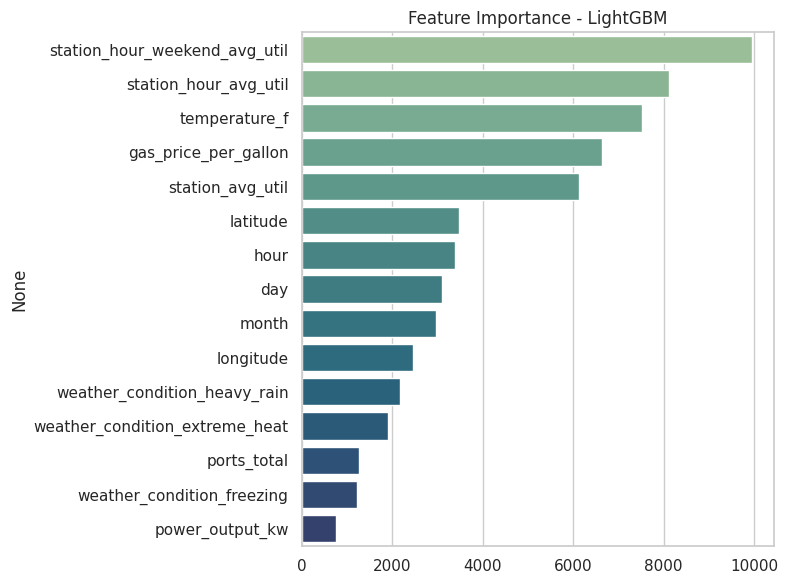

station_hour_weekend_avg_util    9941
station_hour_avg_util            8107
temperature_f                    7527
gas_price_per_gallon             6636
station_avg_util                 6135
latitude                         3468
hour                             3395
day                              3105
month                            2955
longitude                        2453
dtype: int32


In [ ]:
# 5.4 Feature Importance (faktor paling berpengaruh)
def tampilkan_feature_importance(model, nama_model, fitur, top_n=15):
    if hasattr(model, "feature_importances_"):
        importance = pd.Series(model.feature_importances_, index=fitur).sort_values(ascending=False)
    elif hasattr(model, "coef_"):
        importance = pd.Series(np.abs(model.coef_), index=fitur).sort_values(ascending=False)
    else:
        return None
    plt.figure(figsize=(8, 6))
    sns.barplot(x=importance.values[:top_n], y=importance.index[:top_n], palette="crest")
    plt.title(f"Feature Importance - {nama_model}")
    plt.tight_layout()
    plt.show()
    return importance

print(f"\n=== Feature Importance - {model_terbaik_nama} ===")
if is_blend:
    print("(Blend tidak punya feature_importances_ tunggal, tampilkan punya XGBoost sbg komponen utama)")
    importance_terbaik = tampilkan_feature_importance(model_terlatih["XGBoost"], "XGBoost (komponen Blend)", fitur_prediktor)
else:
    importance_terbaik = tampilkan_feature_importance(model_terbaik, model_terbaik_nama, fitur_prediktor)
print(importance_terbaik.head(10) if importance_terbaik is not None else "Tidak tersedia")

# LightGBM
print("\n=== Feature Importance - LightGBM ===")
importance_lgbm = tampilkan_feature_importance(model_terlatih["LightGBM"], "LightGBM", fitur_prediktor)
print(importance_lgbm.head(10))

6. DEPLOYMENT

In [ ]:
# ============================================================
# 6.1 LATIH ULANG MODEL TERBAIK PAKAI SELURUH TRAIN
# ============================================================
if is_ensemble3:
    xgb_best_iter = xgb_model.best_iteration + 1
    lgbm_best_iter = lgbm_model.best_iteration_ + 1
    cb_best_iter = cb_model.get_best_iteration() + 1

    xgb_full_params = {**xgb_params, 'n_estimators': xgb_best_iter}
    xgb_full_params.pop('early_stopping_rounds', None)
    xgb_full = XGBRegressor(**xgb_full_params)
    xgb_full.fit(X, y)

    lgbm_full_params = {**lgbm_params, 'n_estimators': lgbm_best_iter}
    lgbm_full = LGBMRegressor(**lgbm_full_params)
    lgbm_full.fit(X, y)

    X_cb_full = X.copy()
    X_cb_full['station_id'] = station_id_for_cb.values
    X_cb_full['station_id'] = X_cb_full['station_id'].fillna('__MISSING__').astype(str)
    cb_full = CatBoostRegressor(
        iterations=cb_best_iter, learning_rate=0.035, depth=8,
        loss_function='RMSE', l2_leaf_reg=6, random_seed=42,
        random_strength=0.5, border_count=128, verbose=False,
        allow_writing_files=False, thread_count=-1
    )
    cb_full.fit(X_cb_full, y, cat_features=[X_cb_full.columns.get_loc('station_id')])
    print(f'Retrain penuh: XGB={xgb_best_iter}, LGBM={lgbm_best_iter}, CatBoost={cb_best_iter}')

elif is_blend:
    xgb_best_iter = xgb_model.best_iteration + 1
    lgbm_best_iter = lgbm_model.best_iteration_ + 1
    xgb_full_params = {**xgb_params, 'n_estimators': xgb_best_iter}
    xgb_full_params.pop('early_stopping_rounds', None)
    xgb_full = XGBRegressor(**xgb_full_params)
    xgb_full.fit(X, y)
    lgbm_full_params = {**lgbm_params, 'n_estimators': lgbm_best_iter}
    lgbm_full = LGBMRegressor(**lgbm_full_params)
    lgbm_full.fit(X, y)
else:
    model_terbaik.fit(X, y)
    print(f'Retrain penuh selesai | Model: {model_terbaik_nama}')


Retrain penuh: XGB=388, LGBM=533, CatBoost=887


In [ ]:
# 6.2 Load dataset test.csv untuk menentukan hasil prediksi
df_test = pd.read_csv('/content/drive/MyDrive/DATADUO_LOMBA/test.csv')
print("Shape test:", df_test.shape)
id_test = df_test['id']
df_test_source = pd.read_csv('/content/drive/MyDrive/DATADUO_LOMBA/test.csv', usecols=['station_id'])
df_test_raw_original = df_test_source.copy()


Shape test: (263550, 20)


In [ ]:
# 6.3 Terapkan SEMUA langkah preprocessing yang sama seperti Tahap 3 (Data Preparation)
# station_id DIPERTAHANKAN sementara (sama seperti train.csv), dipakai untuk
# menerapkan fitur target-encoding station_avg_util / station_hour_avg_util
# di tahap 6.6b sebelum akhirnya di-drop.
df_test = df_test.drop(columns=['id', 'station_name'])

df_test['timestamp'] = pd.to_datetime(df_test['timestamp'])
df_test['month'] = df_test['timestamp'].dt.month

In [ ]:
#  6.4 Missing value: pakai median per city+month (sama seperti train, tapi dihitung
# dari test.csv sendiri karena kita tidak boleh "mengintip" train.csv di sini)
if df_test['temperature_f'].isnull().sum() > 0:
    df_test['temperature_f'] = df_test.groupby(['city', 'month'])['temperature_f'] \
                                        .transform(lambda x: x.fillna(x.median()))
if df_test['precipitation_mm'].isnull().sum() > 0:
    df_test['precipitation_mm'] = df_test.groupby(['city', 'month'])['precipitation_mm'] \
                                            .transform(lambda x: x.fillna(x.median()))
if df_test['ports_total'].isnull().sum() > 0:
    df_test['ports_total'] = df_test.groupby('city')['ports_total'].transform(lambda x: x.fillna(x.median()))
    df_test['ports_total'] = df_test['ports_total'].astype(int)

# Jaga-jaga: tangani sisa missing value
sisa_numerik_test = df_test.select_dtypes(include=np.number).isnull().sum()
for col in sisa_numerik_test[sisa_numerik_test > 0].index:
    df_test[col] = df_test[col].fillna(df_test[col].median())
sisa_kategorikal_test = df_test.select_dtypes(include='object').isnull().sum()
for col in sisa_kategorikal_test[sisa_kategorikal_test > 0].index:
    df_test[col] = df_test[col].fillna(df_test[col].mode()[0])

print("Missing value test.csv setelah cleaning:", df_test.isnull().sum().sum(), "(harus 0)")

Missing value test.csv setelah cleaning: 0 (harus 0)


In [ ]:
# 6.5 Outlier capping -- pakai batas yang SAMA seperti train.csv (bukan dihitung ulang
# dari test.csv), supaya konsisten dengan apa yang dipelajari model
for col in ['power_output_kw', 'precipitation_mm', 'gas_price_per_gallon']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)  # df = train.csv (Tahap 3)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    df_test[col] = df_test[col].clip(lower, upper)


In [ ]:
# 6.6 Fitur waktu
df_test['hour'] = df_test['timestamp'].dt.hour
df_test['day'] = df_test['timestamp'].dt.dayofweek
df_test['is_weekend'] = df_test['day'].isin([5, 6]).astype(int)
df_test['is_peak_hour'] = df_test['hour'].apply(lambda h: 1 if (7 <= h <= 9) or (17 <= h <= 19) else 0).astype(int)
df_test = df_test.drop(columns=['timestamp'])


In [ ]:
# 6.6b Terapkan target-encoding stasiun (pakai mapping dari TRAIN)
df_test['station_avg_util'] = df_test['station_id'].map(station_avg_map_full).fillna(global_mean)

df_test['station_hour_avg_util'] = df_test.set_index(['station_id', 'hour']).index.map(station_hour_avg_map_full)
df_test['station_hour_avg_util'] = df_test['station_hour_avg_util'].fillna(df_test['station_avg_util'])

df_test['station_hour_weekend_avg_util'] = df_test.set_index(['station_id', 'hour', 'is_weekend']).index.map(station_hour_weekend_avg_map_full)
df_test['station_hour_weekend_avg_util'] = df_test['station_hour_weekend_avg_util'].fillna(df_test['station_hour_avg_util'])

df_test = df_test.drop(columns=['station_id'])
print("Fitur station encoding berhasil diterapkan ke test.csv")

Fitur station encoding berhasil diterapkan ke test.csv


In [ ]:
#  6.7 Fitur amenities_nearby
df_test['jumlah_amenities'] = df_test['amenities_nearby'].apply(lambda x: len(str(x).split(',')))
amenity_list_test = df_test['amenities_nearby'].apply(lambda x: [a.strip() for a in str(x).split(',')])
amenity_encoded_test = pd.DataFrame(
    mlb.transform(amenity_list_test),   # pakai mlb yang SAMA dari train (bukan fit baru!)
    columns=[f"amenity_{a.replace(' ', '_')}" for a in mlb.classes_],
    index=df_test.index
)
df_test = pd.concat([df_test, amenity_encoded_test], axis=1).drop(columns=['amenities_nearby'])


In [ ]:
# 6.8 Encoding kategori nominal
df_test = pd.get_dummies(df_test, columns=kolom_nominal, drop_first=True)


In [ ]:
# ============================================================
# 6.9 PREDIKSI TEST + SUBMISSION
# ============================================================
df_test = df_test.reindex(columns=fitur_prediktor, fill_value=0)
X_submission = df_test[fitur_prediktor]

if is_ensemble3:
    X_cb_test = X_submission.copy()
    X_cb_test['station_id'] = station_id_for_cb.iloc[:0].reindex(X_cb_test.index).fillna('__MISSING__') if False else '__MISSING__'
    # station_id test harus dibaca dari test mentah dan disejajarkan dengan index.
    # Karena df_test dan df asli memakai index yang sama hanya untuk train, buat dari df_test_raw jika tersedia.
    if 'df_test_raw_original' in globals():
        test_station_cb = df_test_raw_original['station_id'].astype(str)
    elif 'df_test_source' in globals() and 'station_id' in df_test_source.columns:
        test_station_cb = df_test_source['station_id'].astype(str)
    else:
        # Fallback: baca kembali test.csv dari path yang sama.
        test_station_cb = pd.read_csv('/content/drive/MyDrive/DATADUO_LOMBA/test.csv', usecols=['station_id'])['station_id'].astype(str)
    X_cb_test['station_id'] = test_station_cb.values
    pred_test_xgb = xgb_full.predict(X_submission)
    pred_test_lgb = lgbm_full.predict(X_submission)
    pred_test_cb = cb_full.predict(X_cb_test)
    prediksi_test = w_xgb*pred_test_xgb + w_lgb*pred_test_lgb + w_cb*pred_test_cb
    print(f'Prediksi Ensemble: XGB={w_xgb:.2f}, LGBM={w_lgb:.2f}, CatBoost={w_cb:.2f}')
elif is_blend:
    prediksi_test = (blend_weight_xgb*xgb_full.predict(X_submission) +
                     (1-blend_weight_xgb)*lgbm_full.predict(X_submission))
else:
    prediksi_test = model_terbaik.predict(X_submission)

prediksi_test = np.clip(prediksi_test, 0, 1)
print('Prediksi selesai. Range:', prediksi_test.min(), '-', prediksi_test.max())


Prediksi Ensemble: XGB=0.28, LGBM=0.49, CatBoost=0.23
Prediksi selesai. Range: 0.013229077194083755 - 0.9904654767246799


In [ ]:
# 6.10 utilization_rate seharusnya di rentang 0.0 - 1.0 -- clip jaga-jaga kalau
# model prediksi sedikit di luar rentang (wajar terjadi di regresi)
prediksi_test = np.clip(prediksi_test, 0.0, 1.0)

submission = pd.DataFrame({'id': id_test, 'utilization_rate': prediksi_test})
submission.to_csv('submission.csv', index=False)
print("submission.csv berhasil dibuat! Jumlah baris:", submission.shape[0])
print(submission.head())

submission.csv berhasil dibuat! Jumlah baris: 263550
           id  utilization_rate
0  TST_0U33RJ          0.962350
1  TST_V0LFA4          0.810748
2  TST_J07LFI          0.617460
3  TST_K4KBB3          0.936973
4  TST_OB0S2M          0.573819


In [ ]:
# Untuk mendownload hasil prediksi nya
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print('\n' + '='*60)
print('RINGKASAN HASIL')
print('='*60)
print(df_hasil.to_string(index=False))
print(f'\nModel terbaik: {model_terbaik_nama}')
if is_ensemble3:
    print(f'Bobot: XGB={w_xgb:.2f}, LGBM={w_lgb:.2f}, CatBoost={w_cb:.2f}')
elif is_blend:
    print(f'Bobot blend: XGB={blend_weight_xgb:.2f}, LGBM={1-blend_weight_xgb:.2f}')
print(f"RMSE Validasi terbaik: {df_hasil.iloc[0]['RMSE Validasi']:.6f}")



RINGKASAN HASIL
                       Model  RMSE Train  RMSE Validasi  MAE Validasi  R2 Validasi  Selisih (Val - Train)
Ensemble (XGB+LGBM+CatBoost)         NaN       0.065347      0.046833     0.950774                    NaN
        Blend (XGB+LightGBM)         NaN       0.065356      0.046851     0.950761                    NaN
                    LightGBM    0.064340       0.065371      0.046884     0.950738               0.001031
                     XGBoost    0.064184       0.065386      0.046847     0.950715               0.001203
                    CatBoost         NaN       0.065442      0.046876     0.950631                    NaN

Model terbaik: Ensemble (XGB+LGBM+CatBoost)
Bobot: XGB=0.28, LGBM=0.49, CatBoost=0.23
RMSE Validasi terbaik: 0.065347
